# Week 9 - Gradient Boosting
## Dataset: FEMA NFIP Claims

This week covers gradient boosting, along with the settings that control it, which are the learning rate, the number of estimators (trees), the tree depth, and regularization. Like a random forest, gradient boosting combines many decision trees, but it builds them in a different way. A random forest grows its trees independently and averages them. Gradient boosting grows them one after another, and each new tree is fit to the mistakes the model is still making, specifically to the gradient of the loss with respect to the current predictions. The final prediction is the starting guess plus the sum of every tree's contribution, with each contribution scaled down by the learning rate.

The question is the same one Weeks 4 to 6 asked of the NFIP data, whether a 2017 claim paid more than $50,000 on the building, with the same 12 features and the same train and test split. That makes this notebook a direct comparison with logistic regression (Week 4), the SVM (Week 5), and the random forest (Week 6), and it is meant as groundwork for Milestone Two.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupShuffleSplit,
                                     RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (GradientBoostingClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             log_loss, RocCurveDisplay)

warnings.filterwarnings('ignore', category=FutureWarning)

columns = ['yearOfLoss', 'amountPaidOnBuildingClaim', 'originalConstructionDate', 'ratedFloodZone',
           'buildingReplacementCost', 'totalBuildingInsuranceCoverage', 'waterDepth',
           'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator', 'primaryResidenceIndicator',
           'postFIRMConstructionIndicator', 'latitude', 'longitude']
df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False, usecols=columns)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] >= 0)].copy()
print('2017 claims with a non-negative building payout:', len(df))

2017 claims with a non-negative building payout: 113398


### Data, features, and splits

The features are recorded water depth, the logs of building replacement cost and coverage, number of floors, construction year, latitude, longitude, and indicators for elevated buildings, primary residences, post-FIRM construction, and A and V flood zones, exactly as in Weeks 4 to 6. Like other tree models, gradient boosting needs no feature scaling and is not thrown off by extreme values such as a recorded depth of 610, so water depth goes in uncapped. The test set is the same 25,261 claims as before. Inside the training set, 20% of the claims are set aside as a validation set, so the model can be watched as it grows without touching the test set. Logistic regression and a random forest with the Week 6 settings are refit as reference points.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['zoneA'] = (zone_letter == 'A').astype(int)
df['zoneV'] = (zone_letter == 'V').astype(int)
df['logReplacementCost'] = np.log10(df['buildingReplacementCost'].clip(lower=1))
df['logCoverage'] = np.log10(df['totalBuildingInsuranceCoverage'].clip(lower=1))
features = ['waterDepth', 'logReplacementCost', 'logCoverage', 'numberOfFloorsInTheInsuredBuilding',
            'elevatedBuildingIndicator', 'primaryResidenceIndicator', 'postFIRMConstructionIndicator',
            'constructionYear', 'latitude', 'longitude', 'zoneA', 'zoneV']
data = df.dropna(subset=features).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
y = (data['amountPaidOnBuildingClaim'] > 50000).astype(int).values
X = data[features]

# Same stratified split as Weeks 4 to 6
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]

# A validation set carved out of the training claims, for watching the model grow tree by tree
fit_pos, val_pos = train_test_split(np.arange(len(train_idx)), test_size=0.2, stratify=y_train, random_state=1)
X_fit, X_val, y_fit, y_val = X_train.iloc[fit_pos], X_train.iloc[val_pos], y_train[fit_pos], y_train[val_pos]
print('Claims used:', len(data), '| share over $50,000:', round(y.mean(), 3))
print('Training claims:', len(train_idx), f'(fit {len(fit_pos)}, validation {len(val_pos)})', '| test claims:', len(test_idx))

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=400, max_features=3, min_samples_leaf=5, n_jobs=-1,
                                random_state=0).fit(X_train, y_train)
p_logit = logit.predict_proba(X_test)[:, 1]
p_forest = forest.predict_proba(X_test)[:, 1]
print(f'Reference test ROC-AUC, logistic regression: {roc_auc_score(y_test, p_logit):.4f}')
print(f'Reference test ROC-AUC, Week 6 random forest settings: {roc_auc_score(y_test, p_forest):.4f}')

Claims used: 101042 | share over $50,000: 0.532
Training claims: 75781 (fit 60624, validation 15157) | test claims: 25261


Reference test ROC-AUC, logistic regression: 0.7789
Reference test ROC-AUC, Week 6 random forest settings: 0.8752


### How boosting builds a model

The first model uses scikit-learn's `GradientBoostingClassifier` with its defaults, 100 trees of depth 3 and a learning rate of 0.1. The left plot tracks the log loss after each tree is added. The right plot follows the predicted probability for three validation claims, to show how the prediction is assembled from many small steps.

Default gradient boosting (100 trees, learning rate 0.1, depth 3) fit in 5.7 seconds
Validation ROC-AUC: 0.8625


Log loss before any tree (predicting the base rate): 0.6911
Validation log loss after 1, 10, and 100 trees: 0.6685, 0.5630, 0.4611


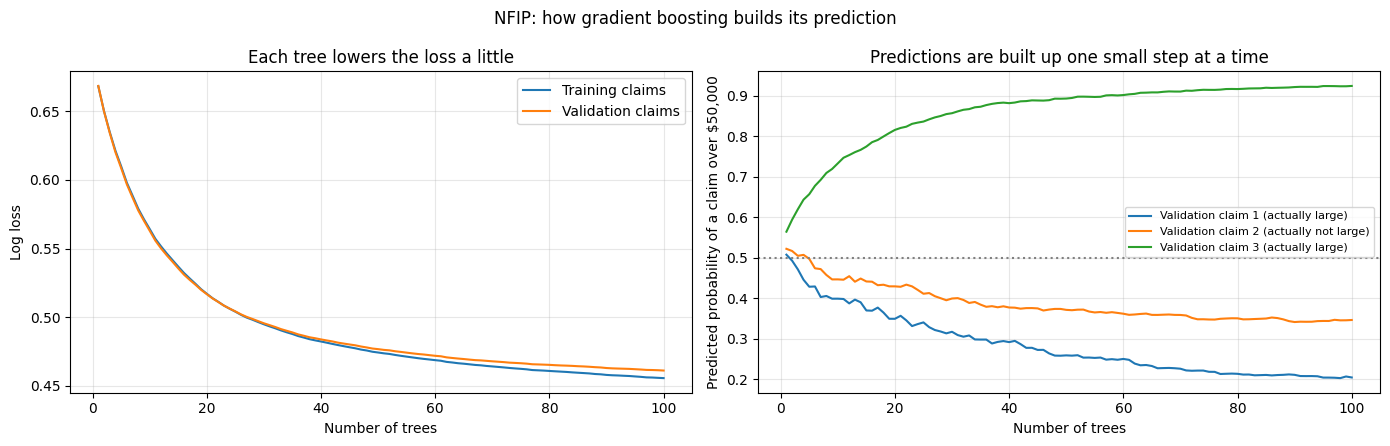

In [3]:
t0 = time.time()
gb = GradientBoostingClassifier(random_state=0).fit(X_fit, y_fit)
print(f'Default gradient boosting (100 trees, learning rate 0.1, depth 3) fit in {time.time() - t0:.1f} seconds')
print(f'Validation ROC-AUC: {roc_auc_score(y_val, gb.predict_proba(X_val)[:, 1]):.4f}')

train_sample = np.random.RandomState(0).choice(len(y_fit), 15000, replace=False)
stages = np.arange(1, gb.n_estimators_ + 1)
train_loss = [log_loss(y_fit[train_sample], p[:, 1]) for p in gb.staged_predict_proba(X_fit.iloc[train_sample])]
val_loss = [log_loss(y_val, p[:, 1]) for p in gb.staged_predict_proba(X_val)]
print(f'Log loss before any tree (predicting the base rate): {log_loss(y_val, np.full(len(y_val), y_fit.mean())):.4f}')
print(f'Validation log loss after 1, 10, and 100 trees: {val_loss[0]:.4f}, {val_loss[9]:.4f}, {val_loss[-1]:.4f}')

# How the predicted probability of three validation claims changes as trees are added
examples = [int(np.argmax(y_val)), int(np.argmin(y_val)), int(len(y_val) // 2)]
paths = np.array([p[examples, 1] for p in gb.staged_predict_proba(X_val)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(stages, train_loss, label='Training claims')
axes[0].plot(stages, val_loss, label='Validation claims')
axes[0].set_xlabel('Number of trees')
axes[0].set_ylabel('Log loss')
axes[0].set_title('Each tree lowers the loss a little')
axes[0].legend()
axes[0].grid(alpha=0.3)
for k, idx in enumerate(examples):
    axes[1].plot(stages, paths[:, k], label=f'Validation claim {k + 1} (actually {"large" if y_val[idx] else "not large"})')
axes[1].axhline(0.5, color='gray', linestyle=':')
axes[1].set_xlabel('Number of trees')
axes[1].set_ylabel('Predicted probability of a claim over $50,000')
axes[1].set_title('Predictions are built up one small step at a time')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.suptitle('NFIP: how gradient boosting builds its prediction')
plt.tight_layout()
plt.show()

Before any tree is fit, the model predicts the base rate (53% large) for every claim, which gives a validation log loss of 0.691. The first tree brings it to 0.669, ten trees to 0.563, and 100 trees to 0.461, for a validation ROC-AUC of 0.863. The right plot shows what that means for single claims. All three start near the base rate, and each tree moves them a little. One large claim climbs to about 0.92 and the claim that was not large settles at about 0.35, both on the right side of 0.5, but the other large claim falls to about 0.20, so the model gets it wrong. With 60,624 claims to learn from, the training and validation curves stay almost on top of each other for the first 100 trees.

### Learning rate and the number of trees

The learning rate and the number of trees work as a pair. A smaller learning rate shrinks each tree's contribution, so the model needs more trees to reach the same fit, but it takes smaller and more careful steps. The next cell fits depth-3 models with learning rates of 1.0, 0.3, 0.1, and 0.03 and records the validation log loss after every tree, so the best number of trees for each rate can be read off the curve.

Took 281 seconds
 Learning rate  Trees fit  Best number of trees  Best validation log loss  Validation ROC-AUC at best  Validation log loss at the last tree
          1.00        300                    90                    0.4570                      0.8679                                0.4836
          0.30        600                   381                    0.4370                      0.8763                                0.4384
          0.10       1500                  1372                    0.4339                      0.8781                                0.4340
          0.03       1500                  1497                    0.4405                      0.8740                                0.4405


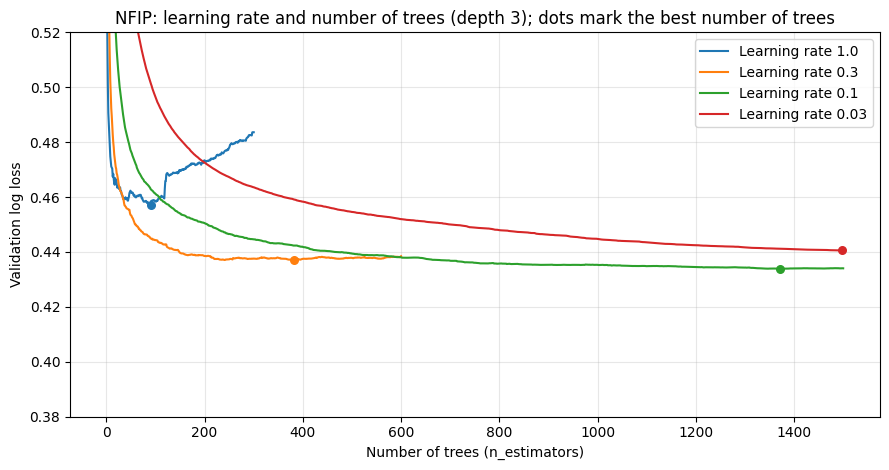

In [4]:
settings = [(1.0, 300), (0.3, 600), (0.1, 1500), (0.03, 1500)]
curves, rows = {}, []
t0 = time.time()
for lr, n in settings:
    m = GradientBoostingClassifier(learning_rate=lr, n_estimators=n, max_depth=3, random_state=0).fit(X_fit, y_fit)
    probs = list(m.staged_predict_proba(X_val))
    losses = np.array([log_loss(y_val, p[:, 1]) for p in probs])
    best = int(np.argmin(losses))
    curves[lr] = losses
    rows.append({'Learning rate': lr, 'Trees fit': n, 'Best number of trees': best + 1,
                 'Best validation log loss': losses[best],
                 'Validation ROC-AUC at best': roc_auc_score(y_val, probs[best][:, 1]),
                 'Validation log loss at the last tree': losses[-1]})
lr_table = pd.DataFrame(rows)
print(f'Took {time.time() - t0:.0f} seconds')
print(lr_table.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.8))
for lr, losses in curves.items():
    line, = ax.plot(np.arange(1, len(losses) + 1), losses, label=f'Learning rate {lr}')
    b = int(np.argmin(losses))
    ax.scatter([b + 1], [losses[b]], color=line.get_color(), zorder=3, s=30)
ax.set_xlabel('Number of trees (n_estimators)')
ax.set_ylabel('Validation log loss')
ax.set_ylim(0.38, 0.52)
ax.set_title('NFIP: learning rate and number of trees (depth 3); dots mark the best number of trees')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The pattern is the classic one. With a learning rate of 1.0 the validation loss is lowest after 90 trees (0.457) and then rises to 0.484 by tree 300, because each tree fully corrects the last and the model starts fitting noise. A learning rate of 0.3 reaches 0.437 at 381 trees and then flattens. A learning rate of 0.1 does best (0.434 at 1,372 trees, validation ROC-AUC 0.878) and barely moves for the last several hundred trees. At 0.03 the loss is still falling at 1,500 trees (0.441), so it would need many more. Smaller steps reach a lower and more stable minimum, at the cost of more trees.

### Tree depth

The depth of each tree sets how many features can interact inside one tree. A depth-1 tree (a stump) splits on a single feature, so a boosted model of stumps is additive, a sum of separate effects for each feature with no interactions. Deeper trees can capture combinations, such as depth mattering more for buildings that are not elevated. The next cell uses `HistGradientBoostingClassifier`, scikit-learn's faster histogram-based version of the same algorithm, with a learning rate of 0.1 and early stopping on the validation claims, which stops adding trees once the validation loss has not improved for 50 trees.

 max_depth  Trees kept by early stopping  Train ROC-AUC  Validation ROC-AUC  Validation log loss  Seconds     Gap
         1                          3000         0.8548              0.8550               0.4714     29.2 -0.0001
         2                          2232         0.8799              0.8740               0.4403     22.5  0.0059
         3                          1243         0.8923              0.8784               0.4330     15.7  0.0139
         5                           512         0.9078              0.8814               0.4285     12.9  0.0264
         8                           214         0.9282              0.8816               0.4284     14.8  0.0466
        12                           123         0.9572              0.8797               0.4330     29.2  0.0775


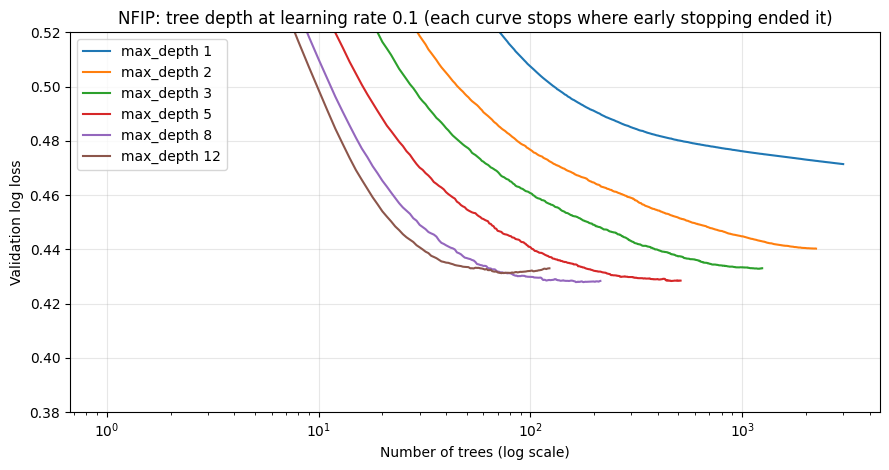

In [5]:
depth_rows, depth_curves = [], {}
for depth in [1, 2, 3, 5, 8, 12]:
    m = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=3000, max_depth=depth, max_leaf_nodes=None,
                                       early_stopping=True, validation_fraction=None, n_iter_no_change=50,
                                       scoring='loss', random_state=0)
    t0 = time.time()
    m.fit(X_fit, y_fit, X_val=X_val, y_val=y_val)
    p_tr, p_va = m.predict_proba(X_fit)[:, 1], m.predict_proba(X_val)[:, 1]
    depth_curves[depth] = -m.validation_score_
    depth_rows.append({'max_depth': depth, 'Trees kept by early stopping': m.n_iter_,
                       'Train ROC-AUC': roc_auc_score(y_fit, p_tr), 'Validation ROC-AUC': roc_auc_score(y_val, p_va),
                       'Validation log loss': log_loss(y_val, p_va), 'Seconds': round(time.time() - t0, 1)})
depth_table = pd.DataFrame(depth_rows)
depth_table['Gap'] = depth_table['Train ROC-AUC'] - depth_table['Validation ROC-AUC']
print(depth_table.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4.8))
for depth, losses in depth_curves.items():
    ax.plot(np.arange(len(losses)), losses, label=f'max_depth {depth}')
ax.set_xscale('log')
ax.set_ylim(0.38, 0.52)
ax.set_xlabel('Number of trees (log scale)')
ax.set_ylabel('Validation log loss')
ax.set_title('NFIP: tree depth at learning rate 0.1 (each curve stops where early stopping ended it)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Stumps reach a validation ROC-AUC of 0.855 and were still improving when they hit the 3,000-tree limit, with no gap at all between training and validation. Depth 3 reaches 0.878, and depths 5 and 8 reach about 0.881 to 0.882 with far fewer trees (512 and 214). Depth 12 is slightly worse (0.880) and has by far the largest gap between training and validation ROC-AUC (0.078, against 0.026 at depth 5). The jump from stumps to depth 3 shows that interactions between features matter for claim size, but past depth 5 the extra depth mostly adds memorization.

### Regularization

Besides the learning rate, the number of trees, and the depth, gradient boosting has several regularizers. The next cell changes one at a time from the default, an L2 penalty on the leaf values (`l2_regularization`), the minimum number of claims in a leaf (`min_samples_leaf`), the share of features each split may consider (`max_features`), and stochastic boosting, where each tree is fit to a random half of the training claims (`subsample`). Early stopping on the validation claims chooses the number of trees in every case.

Each row changes one setting from the default (learning rate 0.1, 31 leaves, min_samples_leaf 20, no L2 penalty)
                           Regularizer  Setting  Trees kept  Train ROC-AUC  Validation ROC-AUC    Gap
                     l2_regularization      0.0         452         0.9206              0.8819 0.0387
                     l2_regularization      1.0         459         0.9184              0.8815 0.0368
                     l2_regularization     10.0         649         0.9162              0.8824 0.0338
                     l2_regularization    100.0         907         0.9041              0.8819 0.0222
                      min_samples_leaf      1.0         335         0.9144              0.8796 0.0348
                      min_samples_leaf     20.0         452         0.9206              0.8819 0.0387
                      min_samples_leaf    100.0         481         0.9160              0.8819 0.0342
                      min_samples_leaf    500.0         469         0.9

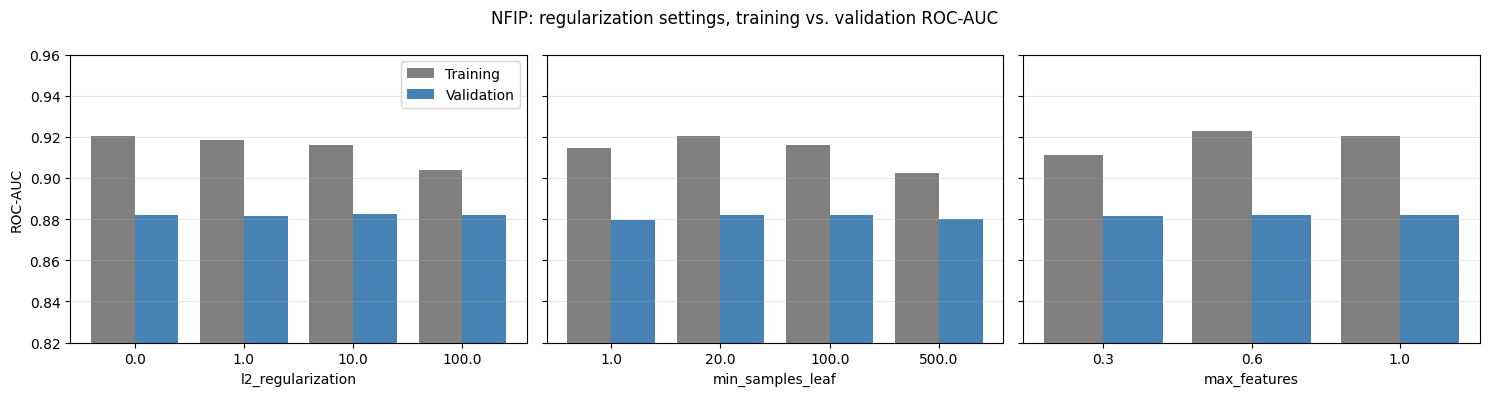

In [6]:
def hgb_check(label, setting, **params):
    base = dict(learning_rate=0.1, max_iter=3000, early_stopping=True, validation_fraction=None,
                n_iter_no_change=50, scoring='loss', random_state=0)
    base.update(params)
    m = HistGradientBoostingClassifier(**base).fit(X_fit, y_fit, X_val=X_val, y_val=y_val)
    p_tr, p_va = m.predict_proba(X_fit)[:, 1], m.predict_proba(X_val)[:, 1]
    return {'Regularizer': label, 'Setting': setting, 'Trees kept': m.n_iter_,
            'Train ROC-AUC': roc_auc_score(y_fit, p_tr), 'Validation ROC-AUC': roc_auc_score(y_val, p_va)}


reg_rows = []
for l2 in [0, 1, 10, 100]:
    reg_rows.append(hgb_check('l2_regularization', l2, l2_regularization=l2))
for leaf in [1, 20, 100, 500]:
    reg_rows.append(hgb_check('min_samples_leaf', leaf, min_samples_leaf=leaf))
for frac in [0.3, 0.6, 1.0]:
    reg_rows.append(hgb_check('max_features', frac, max_features=frac))

# Stochastic gradient boosting: each tree sees a random half of the claims
for sub in [1.0, 0.5]:
    m = GradientBoostingClassifier(learning_rate=0.1, n_estimators=400, max_depth=3, subsample=sub,
                                   random_state=0).fit(X_fit, y_fit)
    losses = [log_loss(y_val, p[:, 1]) for p in m.staged_predict_proba(X_val)]
    best = int(np.argmin(losses)) + 1
    m_best = GradientBoostingClassifier(learning_rate=0.1, n_estimators=best, max_depth=3, subsample=sub,
                                        random_state=0).fit(X_fit, y_fit)
    reg_rows.append({'Regularizer': 'subsample (GradientBoostingClassifier)', 'Setting': sub, 'Trees kept': best,
                     'Train ROC-AUC': roc_auc_score(y_fit, m_best.predict_proba(X_fit)[:, 1]),
                     'Validation ROC-AUC': roc_auc_score(y_val, m_best.predict_proba(X_val)[:, 1])})
reg = pd.DataFrame(reg_rows)
reg['Gap'] = reg['Train ROC-AUC'] - reg['Validation ROC-AUC']
print('Each row changes one setting from the default (learning rate 0.1, 31 leaves, min_samples_leaf 20, no L2 penalty)')
print(reg.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, name in zip(axes, ['l2_regularization', 'min_samples_leaf', 'max_features']):
    part = reg[reg['Regularizer'] == name]
    x = np.arange(len(part))
    ax.bar(x - 0.2, part['Train ROC-AUC'], width=0.4, color='gray', label='Training')
    ax.bar(x + 0.2, part['Validation ROC-AUC'], width=0.4, color='steelblue', label='Validation')
    ax.set_xticks(x)
    ax.set_xticklabels(part['Setting'].astype(str))
    ax.set_xlabel(name)
    ax.set_ylim(0.82, 0.96)
    ax.grid(alpha=0.3, axis='y')
axes[0].set_ylabel('ROC-AUC')
axes[0].legend()
fig.suptitle('NFIP: regularization settings, training vs. validation ROC-AUC')
plt.tight_layout()
plt.show()

The regularizers mostly shrink the gap between training and validation without moving validation accuracy. An L2 penalty of 100 cuts the gap from 0.039 to 0.022 but leaves validation ROC-AUC at 0.882, and it needs about twice as many trees (907 against 452) because each tree's contribution is smaller. Leaves of 500 claims also cut the gap (0.022) with almost no loss, while leaves of a single claim do slightly worse (0.880). Letting each split see only 30% of the features cuts the gap to 0.029 at no cost. Stochastic boosting gave a tiny gain (0.8738 against 0.8733). Every histogram-based setting falls between 0.880 and 0.882 on the validation claims, so with 60,000 claims to learn from, there is not much overfitting left for these settings to remove once the learning rate and early stopping are in place.

### Tuning everything together

The settings interact, so the last step searches them together with `RandomizedSearchCV`, trying 30 random combinations of learning rate, leaf count, depth, leaf size, L2 penalty, and feature share, each scored by 5-fold cross-validation. Early stopping inside each fit chooses the number of trees from an internal 10% validation split, which is fine here because the claims were split at random in every earlier week, and Week 4 showed that predictions hold up when whole areas are held out.

In [7]:
param_dist = {'learning_rate': loguniform(0.02, 0.3),
              'max_leaf_nodes': [15, 31, 63, 127],
              'max_depth': [None, 4, 6, 8],
              'min_samples_leaf': [10, 20, 50, 100, 200],
              'l2_regularization': [0, 0.1, 1, 10],
              'max_features': [0.5, 0.75, 1.0]}
hgb = HistGradientBoostingClassifier(max_iter=3000, early_stopping=True, validation_fraction=0.1,
                                     n_iter_no_change=50, scoring='loss', random_state=0)
search = RandomizedSearchCV(hgb, param_dist, n_iter=30, scoring='roc_auc', n_jobs=4, random_state=0,
                            cv=StratifiedKFold(5, shuffle=True, random_state=0), return_train_score=True)
t0 = time.time()
search.fit(X_train, y_train)
print(f'Randomized search of 30 settings x 5 folds took {time.time() - t0:.0f} seconds')
res = pd.DataFrame(search.cv_results_)
cols = ['param_learning_rate', 'param_max_leaf_nodes', 'param_max_depth', 'param_min_samples_leaf',
        'param_l2_regularization', 'param_max_features', 'mean_train_score', 'mean_test_score']
print(res.sort_values('mean_test_score', ascending=False)[cols].head(6).round(4).to_string(index=False))
print()
print('Best settings:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()})
print(f'Best CV ROC-AUC: {search.best_score_:.4f} | trees kept in the refit: {search.best_estimator_.n_iter_}')
print(f'Spread of CV ROC-AUC across all 30 settings: {res["mean_test_score"].min():.4f} to {res["mean_test_score"].max():.4f}')

Randomized search of 30 settings x 5 folds took 432 seconds
 param_learning_rate  param_max_leaf_nodes param_max_depth  param_min_samples_leaf  param_l2_regularization  param_max_features  mean_train_score  mean_test_score
              0.0295                   127               8                      50                      0.1                0.50            0.9140           0.8798
              0.0341                    63            None                      10                      0.1                0.75            0.9210           0.8797
              0.0570                    63            None                      50                      0.0                0.75            0.9154           0.8796
              0.0288                    31            None                      10                      1.0                0.75            0.9094           0.8796
              0.0366                    63            None                      10                      0.0                0.

### Final evaluation on the held-out test set

Test claims: 25261
                                          Model  Accuracy  Balanced acc.     F1  Log loss  ROC-AUC
                                 Majority class    0.5323         0.5000 0.6948    0.6911   0.5000
                            Logistic regression    0.7145         0.7056 0.7586    0.5771   0.7789
                Random forest (Week 6 settings)    0.7856         0.7833 0.8027    0.4388   0.8752
            Gradient boosting, default settings    0.7736         0.7700 0.7949    0.4642   0.8603
Gradient boosting, tuned (HistGradientBoosting)    0.7940         0.7913 0.8116    0.4308   0.8795



Tuned model, training ROC-AUC 0.9104 vs. test ROC-AUC 0.8795


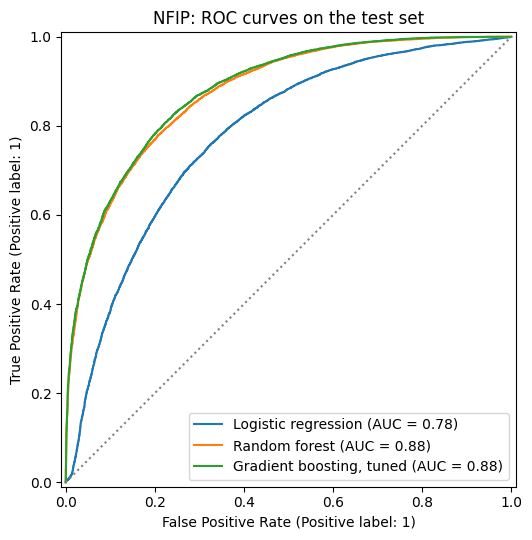

In [8]:
def scores(name, prob):
    pred = (prob >= 0.5).astype(int)
    return {'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Balanced acc.': balanced_accuracy_score(y_test, pred),
            'F1': f1_score(y_test, pred), 'Log loss': log_loss(y_test, prob), 'ROC-AUC': roc_auc_score(y_test, prob)}


best = search.best_estimator_
default_gb = GradientBoostingClassifier(random_state=0).fit(X_train, y_train)
p_default = default_gb.predict_proba(X_test)[:, 1]
p_best = best.predict_proba(X_test)[:, 1]
results = pd.DataFrame([
    scores('Majority class', np.full(len(y_test), y_train.mean())),
    scores('Logistic regression', p_logit),
    scores('Random forest (Week 6 settings)', p_forest),
    scores('Gradient boosting, default settings', p_default),
    scores('Gradient boosting, tuned (HistGradientBoosting)', p_best),
])
print('Test claims:', len(y_test))
print(results.round(4).to_string(index=False))
print()
print(f'Tuned model, training ROC-AUC {roc_auc_score(y_train, best.predict_proba(X_train)[:, 1]):.4f} '
      f'vs. test ROC-AUC {roc_auc_score(y_test, p_best):.4f}')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, prob in [('Logistic regression', p_logit), ('Random forest', p_forest), ('Gradient boosting, tuned', p_best)]:
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
ax.set_title('NFIP: ROC curves on the test set')
plt.tight_layout()
plt.show()

Permutation importance (drop in test ROC-AUC when the feature is shuffled):
longitude                             0.0728
logReplacementCost                    0.0657
latitude                              0.0504
waterDepth                            0.0490
logCoverage                           0.0414
elevatedBuildingIndicator             0.0189
constructionYear                      0.0133
zoneA                                 0.0114
numberOfFloorsInTheInsuredBuilding    0.0105
postFIRMConstructionIndicator         0.0026
primaryResidenceIndicator             0.0021
zoneV                                 0.0002


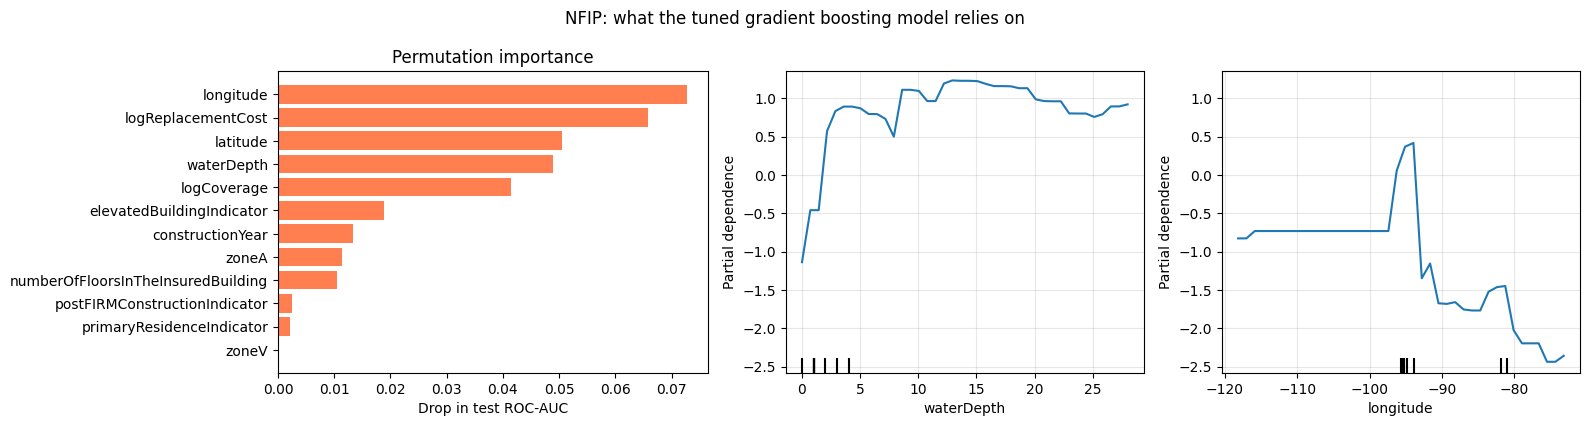

In [9]:
perm = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=0, n_jobs=4)
imp = pd.Series(perm.importances_mean, index=features).sort_values()
print('Permutation importance (drop in test ROC-AUC when the feature is shuffled):')
print(imp.iloc[::-1].round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={'width_ratios': [1.2, 1, 1]})
axes[0].barh(imp.index, imp.values, color='coral')
axes[0].set_xlabel('Drop in test ROC-AUC')
axes[0].set_title('Permutation importance')
PartialDependenceDisplay.from_estimator(best, X_train.sample(3000, random_state=0), ['waterDepth', 'longitude'],
                                        percentiles=(0.01, 0.99), grid_resolution=40, ax=axes[1:])
for ax in axes[1:]:
    ax.grid(alpha=0.3)
fig.suptitle('NFIP: what the tuned gradient boosting model relies on')
plt.tight_layout()
plt.show()

The tuned model reaches a test ROC-AUC of 0.880, with an accuracy of 0.794, a balanced accuracy of 0.791, an F1 of 0.812, and a log loss of 0.431. That beats the random forest (0.875, log loss 0.439), default gradient boosting (0.860), and logistic regression (0.779) on the same test claims. Its training ROC-AUC is 0.910, a gap of 0.031.

Permutation importance ranks longitude first (a 0.073 drop in test ROC-AUC when shuffled), then replacement cost (0.066), latitude (0.050), water depth (0.049), and coverage (0.041), much like the random forest in Week 6. The partial dependence plots are on the log-odds scale. The water depth effect jumps sharply over the first two or three units of depth and then stays roughly level with some noise, the same rise and plateau found by every model since Week 1. Longitude peaks sharply around -95 to -94 degrees, the Houston area, and is lowest across Florida, which once again separates Hurricane Harvey from Hurricane Irma.

### Is the model memorizing neighborhoods?

Trees can carve latitude and longitude into small boxes, so the next cell repeats the location check from earlier weeks, holding out whole cells of 0.1 degrees of latitude and longitude.

In [10]:
cells_id = data['latitude'].round(1).astype(str) + '_' + data['longitude'].round(1).astype(str)
g_train, g_test = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(X, y, cells_id))
rows = []
for name, model in [('Random forest (Week 6 settings)', RandomForestClassifier(n_estimators=400, max_features=3, min_samples_leaf=5,
                                                                               n_jobs=-1, random_state=0)),
                    ('Gradient boosting, tuned', HistGradientBoostingClassifier(**{**best.get_params()}))]:
    model.fit(X.iloc[g_train], y[g_train])
    rows.append({'Model': name, 'Random split AUC': roc_auc_score(y_test, p_forest if 'forest' in name else p_best),
                 'Location-cell split AUC': roc_auc_score(y[g_test], model.predict_proba(X.iloc[g_test])[:, 1])})
loc = pd.DataFrame(rows)
loc['Drop'] = loc['Random split AUC'] - loc['Location-cell split AUC']
print('Location cells:', cells_id.nunique(), '| shared between train and test:', len(set(cells_id.iloc[g_train]) & set(cells_id.iloc[g_test])))
print(loc.round(4).to_string(index=False))

Location cells: 3580 | shared between train and test: 0
                          Model  Random split AUC  Location-cell split AUC   Drop
Random forest (Week 6 settings)            0.8752                   0.8664 0.0089
       Gradient boosting, tuned            0.8795                   0.8672 0.0123


Holding out whole location cells lowers the tuned model from 0.880 to 0.867, a drop of 0.012, slightly more than the random forest's drop of 0.009. The two models end up almost tied on unseen areas (0.867 against 0.866), so part of boosting's small edge on the random split comes from fitting local detail. Neither model is mainly memorizing neighbors.

## Discussion

### Overfitting

Gradient boosting overfits in a different way from a random forest. Adding trees to a forest only makes it more stable, but every new boosting tree fits the training data more closely, so the model eventually starts fitting noise. The learning rate curves show this directly, with the validation loss at a learning rate of 1.0 rising from 0.457 at 90 trees to 0.484 at 300. Several controls kept it in check. A small learning rate made each step small, early stopping on validation claims chose the number of trees, a moderate depth limited how much each tree could memorize (the gap rose from 0.026 at depth 5 to 0.078 at depth 12), and the regularizers trimmed the remaining gap. The tuned model's training and test ROC-AUC differ by 0.031, and the location check confirms that its test score is not built on recognizing neighbors.

### Metrics and hyperparameter tuning

ROC-AUC was the main metric, as in Weeks 4 to 6, because it measures how well the model ranks large claims above smaller ones without depending on a single cutoff. Log loss was used to track the model as it grew, since it is the quantity gradient boosting minimizes. The tuned settings and what they mean are as follows. The learning rate (0.03) shrinks each tree's contribution, so smaller values need more trees but reach a better minimum. Early stopping kept 734 trees, the number of correction steps. A depth of 8 with up to 127 leaves sets how many features can combine in one tree. A minimum leaf size of 50 claims keeps a tree from making a rule out of a few claims, an L2 penalty of 0.1 slightly shrinks the leaf values, and considering half the features at each split makes the trees less alike. Across the 30 combinations, cross-validated ROC-AUC ranged only from 0.874 to 0.880, so for this dataset the exact settings matter much less than having a small learning rate, enough trees, and early stopping.

### Expected or unexpected

I expected tuned boosting to match the random forest, and it did slightly better (0.880 against 0.875). I did not expect default boosting to do so much worse (0.860). The default stops at 100 trees with a learning rate of 0.1, but the learning rate curves show this data needs more than 1,000 trees at that rate, so the default is simply stopping early.

The flat tuning results were also a surprise after Week 5, where the SVM was sensitive to every setting. Here almost any reasonable combination lands within 0.006 of the best. And as with the forest, longitude is the top feature, which says more about which storm hit than about the buildings themselves.

### How EDA helped

The rise and plateau in water depth, first seen in the Module B EDA and confirmed in every week since, made it easy to check that the boosted model's partial dependence was sensible. The extreme values found in the raw-scale table in Week 4 (depths up to 610 and replacement costs near $967 million) are why a tree-based model that ignores them is a good fit here. And the Week 1 finding that the storm is one of the strongest predictors explains why longitude, the model's only way to tell Harvey from Irma, comes out on top.

### External sources

- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics*, 29(5), 1189-1232.
- scikit-learn User Guide, "Gradient-boosted trees," including early stopping and the histogram-based estimators: https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosted-trees
- scikit-learn example, "Gradient Boosting regularization," which compares shrinkage, subsampling, and feature subsampling: https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_regularization.html
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.), Chapter 10 ("Boosting and Additive Trees").

### Conclusions

Tuned gradient boosting predicts whether a 2017 NFIP claim paid more than $50,000 with a test ROC-AUC of 0.880, the best result on this question so far, ahead of the random forest (0.875), the SVM (0.834), and logistic regression (0.809 at its best). The learning rate and the number of trees mattered most. A small learning rate with early stopping beat the default settings by 0.02, while the other regularizers and the exact tree size made little difference. The model finds the same depth curve and the same storm-driven location effect as the earlier models, which makes the results easy to trust.

For Milestone Two and the Capstone, gradient boosting is the strongest model for NFIP claim severity so far, and the remaining gains will have to come from better features, not more tuning. Replacing longitude with direct measures of storm intensity and adding the land cover and property value data from the proposal are the clearest next steps.